# Notebook 07 — Feature Engineering

**Projet : Predictive Maintenance MLOps — MetroPT-3**

## Objectif
Construire une première version limitée et justifiée de variables dérivées, afin de préparer un pipeline ML reproductible.

Ce notebook ne cherche pas à optimiser le modèle. Les variables créées sont des **candidates** : leur intérêt sera mesuré ultérieurement par comparaison avec la baseline, avec le même protocole de validation LOEO.

### Variables créées
1. Différences temporelles de `TP2`, `Oil_temperature` et `Motor_current`.
2. Moyennes mobiles causales sur 1 et 5 minutes pour ces mêmes variables.
3. Écarts physiques `TP3 - Reservoirs` et `TP2 - TP3`.

### Règles méthodologiques
- Aucune utilisation de `target_event` ou `event_id` comme variable explicative.
- Les transformations temporelles utilisent uniquement l'observation courante et le passé.
- Les différences ne sont calculées que si deux observations consécutives sont séparées de 30 secondes maximum.
- Les fenêtres glissantes sont réinitialisées après une interruption supérieure à 30 secondes.
- Les paramètres sont explicites et devront être identiques en entraînement et en inférence.


## 1. Imports et configuration

In [2]:
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42
MAX_GAP_SECONDS = 30

ROLLING_WINDOWS = {
    "1min": pd.Timedelta("1min"),
    "5min": pd.Timedelta("5min"),
}

# Chemins relatifs à la racine du dépôt.
PROJECT_ROOT = Path("..").resolve()
CONFIG_PATH = PROJECT_ROOT / "config.yaml"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print("Racine du projet :", PROJECT_ROOT)
print("Configuration chargée :", CONFIG_PATH)


Racine du projet : C:\Users\ngueb\Desktop\Prédictive_maintenance_MLOPS
Configuration chargée : C:\Users\ngueb\Desktop\Prédictive_maintenance_MLOPS\config.yaml


## 2. Chargement du dataset labellisé

Le `config.yaml` fourni ne définit pas encore de chemin pour le dataset traité. Le code ci-dessous recherche donc les CSV du dossier `data/processed` qui contiennent les colonnes attendues. Si plusieurs fichiers correspondent, sélectionne explicitement le bon fichier dans `DATA_PATH`.

In [3]:
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "MetroPT3_labeled.csv"

required_columns = {"timestamp", "target_event", "event_id"}

if DATA_PATH is None:
    candidates = []
    processed_dir = PROJECT_ROOT / "data" / "processed"
    if processed_dir.exists():
        for path in processed_dir.glob("*.csv"):
            try:
                cols = set(pd.read_csv(path, nrows=0).columns)
                if required_columns.issubset(cols):
                    candidates.append(path)
            except Exception:
                continue

    if len(candidates) == 0:
        raise FileNotFoundError(
            "Aucun CSV labellisé contenant timestamp, target_event et event_id "
            "n'a été trouvé dans data/processed. Renseigne DATA_PATH manuellement."
        )
    if len(candidates) > 1:
        raise ValueError(
            "Plusieurs datasets labellisés trouvés. Renseigne DATA_PATH explicitement :\n"
            + "\n".join(str(p) for p in candidates)
        )
    DATA_PATH = candidates[0]

df = pd.read_csv(DATA_PATH)
missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"Colonnes obligatoires absentes : {sorted(missing)}")

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
if df["timestamp"].isna().any():
    raise ValueError("Des timestamps invalides sont présents.")

df = df.sort_values("timestamp").reset_index(drop=True)
if df["timestamp"].duplicated().any():
    raise ValueError("Des timestamps dupliqués sont présents.")

df = df.set_index("timestamp")
if not df.index.is_monotonic_increasing:
    raise ValueError("Les données ne sont pas triées chronologiquement.")

print("Dataset :", DATA_PATH)
print("Dimensions :", df.shape)
print("Période :", df.index.min(), "→", df.index.max())
print("Intervalle médian (s) :", df.index.to_series().diff().dt.total_seconds().median())
display(df.head())


Dataset : C:\Users\ngueb\Desktop\Prédictive_maintenance_MLOPS\data\processed\MetroPT3_labeled.csv
Dimensions : (1516948, 18)
Période : 2020-02-01 00:00:00 → 2020-09-01 03:59:50
Intervalle médian (s) : 10.0


,Unnamed: 0,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses,target_event,event_id
timestamp,,,,,,,,,,,,,,,,,,
2020-02-01 00:00:00,0,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN
2020-02-01 00:00:10,10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN
2020-02-01 00:00:19,20,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN
2020-02-01 00:00:29,30,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN
2020-02-01 00:00:39,40,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN


## 3. Définition des variables initiales

In [4]:
baseline_features = config["features"]["baseline"]

numeric_features = config["features"]["categorical"]

digital_features = config["features"]["numeric"]

required_sensor_features = numeric_features + digital_features
missing_features = [c for c in required_sensor_features if c not in df.columns]
if missing_features:
    raise ValueError(f"Variables capteurs absentes : {missing_features}")

# Vérifier que les variables baseline définies dans la configuration sont présentes.
missing_baseline = [c for c in baseline_features if c not in df.columns]
if missing_baseline:
    raise ValueError(f"Variables baseline absentes : {missing_baseline}")

print("Nombre de variables baseline :", len(baseline_features))
print("Nombre de variables numériques :", len(numeric_features))
print("Nombre de variables digitales :", len(digital_features))


Nombre de variables baseline : 15
Nombre de variables numériques : 8
Nombre de variables digitales : 7


## 4. Contrôle de la régularité temporelle et segmentation

Les données sont irrégulières. Pour éviter de calculer une différence ou une moyenne glissante à travers une longue interruption, nous créons des segments temporels. Un nouveau segment commence lorsqu'un intervalle entre deux mesures dépasse 30 secondes.

**30 secondes est un choix opérationnel pour cette première expérimentation**, fondé sur la fréquence médiane observée d'environ 10 secondes. Ce seuil devra être documenté et pourra être testé ultérieurement.

In [5]:
time_delta = df.index.to_series().diff()
time_delta_seconds = time_delta.dt.total_seconds()

# Une nouvelle séquence commence après un intervalle > 30 s.
new_segment = time_delta_seconds.isna() | (time_delta_seconds > MAX_GAP_SECONDS)
segment_id = new_segment.cumsum().astype("int64")

interval_summary = time_delta_seconds.describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
)
display(interval_summary.to_frame("interval_seconds"))

print("Nombre de segments :", segment_id.nunique())
print("Proportion des intervalles > 30 s :",
      round((time_delta_seconds > MAX_GAP_SECONDS).mean() * 100, 3), "%")


,interval_seconds
count,1.516947e+06
mean,1.214122e+01
std,3.141073e+02
min,8.000000e+00
50%,1.000000e+01
90%,1.000000e+01
95%,1.000000e+01
99%,1.200000e+01
max,1.729180e+05


Nombre de segments : 332
Proportion des intervalles > 30 s : 0.022 %


## 5. Création des différences temporelles

Pour une variable \(x\), la différence est :

\[
\Delta x_t = x_t - x_{t-1}
\]

Elle représente le changement entre deux mesures consécutives. Nous ne la calculons que si l'intervalle est positif et inférieur ou égal à 30 secondes.

In [6]:
df_fe = df.copy()

difference_features = ["TP2", "Oil_temperature", "Motor_current"]

valid_consecutive = (
    time_delta_seconds.gt(0)
    & time_delta_seconds.le(MAX_GAP_SECONDS)
)

for col in difference_features:
    diff_col = f"{col}_diff"
    diff_values = df[col].diff()
    df_fe[diff_col] = diff_values.where(valid_consecutive)

difference_columns = [f"{c}_diff" for c in difference_features]
display(df_fe[difference_columns].describe().T)


,count,mean,std,min,25%,50%,75%,max
TP2_diff,1516616.0,-0.000490,1.096696,-10.696,0.0000,0.00,0.0020,8.5820
Oil_temperature_diff,1516616.0,0.002017,0.308618,-8.700,-0.1250,-0.05,0.0250,3.1250
Motor_current_diff,1516616.0,-0.000626,0.557673,-6.185,-0.0025,0.00,0.0025,9.2525


## 6. Création des moyennes mobiles causales

Les moyennes mobiles résument le niveau récent d'un capteur. Les fenêtres sont temporelles (1 et 5 minutes), et non définies par un nombre fixe de lignes, car l'échantillonnage est irrégulier.

La fenêtre inclut l'observation courante et les observations antérieures disponibles : elle est donc utilisable dans un scénario de prédiction en ligne. Elle est calculée séparément dans chaque segment temporel.

In [7]:
rolling_features = ["TP2", "Oil_temperature", "Motor_current"]
MIN_PERIODS = {
    "1min": 3,
    "5min": 5,
}

for col in rolling_features:
    for window_name, window_size in ROLLING_WINDOWS.items():
        feature_name = f"{col}_rolling_mean_{window_name}"

        # Calcul segment par segment : aucune fenêtre ne traverse une longue interruption.
        rolling_result = (
            df.groupby(segment_id, sort=False)[col]
              .rolling(window=window_size, min_periods=MIN_PERIODS[window_name])
              .mean()
        )

        # Le MultiIndex (segment, timestamp) est ramené à l'index temporel.
        rolling_result.index = rolling_result.index.get_level_values(-1)
        df_fe[feature_name] = rolling_result.reindex(df.index)

rolling_mean_columns = [
    f"{col}_rolling_mean_{window}"
    for col in rolling_features
    for window in ROLLING_WINDOWS
]

display(df_fe[rolling_mean_columns].describe().T)


,count,mean,std,min,25%,50%,75%,max
TP2_rolling_mean_1min,1516284.0,1.368291,3.044170,-0.026667,-0.013429,-0.011714,-0.009667,10.497000
TP2_rolling_mean_5min,1515620.0,1.373050,2.322753,-0.020400,-0.012774,-0.010903,2.588129,10.250710
Oil_temperature_rolling_mean_1min,1516284.0,62.643193,6.497331,15.425000,57.770833,62.737500,67.242857,88.920833
Oil_temperature_rolling_mean_5min,1515620.0,62.628845,6.278584,15.680000,57.936290,63.032258,67.148387,88.620968
Motor_current_rolling_mean_1min,1516284.0,2.050660,2.223187,0.020000,0.041071,0.045000,3.797857,6.406667
Motor_current_rolling_mean_5min,1515620.0,2.056002,1.907283,0.020484,0.042097,1.828427,3.781855,6.237083


## 7. Création des variables d'interaction physique

Deux écarts sont ajoutés comme variables candidates :

- `TP3 - Reservoirs` : écart entre la pression au panneau pneumatique et celle mesurée en aval des réservoirs. Les deux signaux étaient presque parfaitement corrélés dans l'analyse précédente ; cette variable pourrait donc être redondante.
- `TP2 - TP3` : différence entre la pression du compresseur et celle du panneau pneumatique.

Ces écarts ne sont pas considérés comme des indicateurs de panne validés. Leur intérêt sera évalué par expérimentation.

In [8]:
df_fe["pressure_gap_TP3_Reservoirs"] = df_fe["TP3"] - df_fe["Reservoirs"]
df_fe["pressure_gap_TP2_TP3"] = df_fe["TP2"] - df_fe["TP3"]

interaction_features = [
    "pressure_gap_TP3_Reservoirs",
    "pressure_gap_TP2_TP3"
]

display(df_fe[interaction_features].describe().T)


,count,mean,std,min,25%,50%,75%,max
pressure_gap_TP3_Reservoirs,1516948.0,-0.000623,0.002452,-0.182,-0.002,0.000,0.000,0.028
pressure_gap_TP2_TP3,1516948.0,-7.616785,3.320145,-10.306,-9.396,-8.808,-8.278,0.842


## 8. Inventaire et contrôles des nouvelles variables

In [9]:
engineered_features = (
    difference_columns
    + rolling_mean_columns
    + interaction_features
)

print("Nombre de variables initiales :", len(baseline_features))
print("Nombre de variables créées :", len(engineered_features))
print("Nombre total de variables candidates :",
      len(baseline_features) + len(engineered_features))

feature_inventory = pd.DataFrame({
    "feature": engineered_features,
    "family": (
        ["difference"] * len(difference_columns)
        + ["rolling_mean"] * len(rolling_mean_columns)
        + ["physical_interaction"] * len(interaction_features)
    ),
    "missing_rate": [df_fe[c].isna().mean() for c in engineered_features],
    "n_unique": [df_fe[c].nunique(dropna=True) for c in engineered_features],
})

display(feature_inventory)


Nombre de variables initiales : 15
Nombre de variables créées : 11
Nombre total de variables candidates : 26


,feature,family,missing_rate,n_unique
0,TP2_diff,difference,0.000219,21056
1,Oil_temperature_diff,difference,0.000219,976
2,Motor_current_diff,difference,0.000219,11947
3,TP2_rolling_mean_1min,rolling_mean,0.000438,108245
4,TP2_rolling_mean_5min,rolling_mean,0.000875,287714
5,Oil_temperature_rolling_mean_1min,rolling_mean,0.000438,47818
6,Oil_temperature_rolling_mean_5min,rolling_mean,0.000875,97020
7,Motor_current_rolling_mean_1min,rolling_mean,0.000438,60171
8,Motor_current_rolling_mean_5min,rolling_mean,0.000875,205197
9,pressure_gap_TP3_Reservoirs,physical_interaction,0.000000,143


In [10]:
# Contrôles de cohérence : les variables cibles et identifiants ne sont pas des features.
forbidden_features = {"target_event", "event_id", "timestamp", "Unnamed: 0"}
assert not (set(engineered_features) & forbidden_features)

# Vérification des valeurs infinies.
numeric_engineered = df_fe[engineered_features].select_dtypes(include=np.number)
infinite_counts = np.isinf(numeric_engineered.to_numpy()).sum()
print("Nombre de valeurs infinies dans les variables créées :", infinite_counts)

# Contrôle des valeurs manquantes : elles sont attendues au début des fenêtres
# et après les interruptions. Elles ne doivent pas être imputées ici à l'aveugle.
display(
    df_fe[engineered_features].isna().mean()
    .rename("missing_rate")
    .to_frame()
)


Nombre de valeurs infinies dans les variables créées : 0


,missing_rate
TP2_diff,0.000219
Oil_temperature_diff,0.000219
Motor_current_diff,0.000219
TP2_rolling_mean_1min,0.000438
TP2_rolling_mean_5min,0.000875
Oil_temperature_rolling_mean_1min,0.000438
Oil_temperature_rolling_mean_5min,0.000875
Motor_current_rolling_mean_1min,0.000438
Motor_current_rolling_mean_5min,0.000875
pressure_gap_TP3_Reservoirs,0.000000


## 9. Analyse descriptive des variables créées

,count,mean,std,min,25%,50%,75%,max
TP2_diff,1516616.0,-0.000490,1.096696,-10.696000,0.000000,0.000000,0.002000,8.582000
Oil_temperature_diff,1516616.0,0.002017,0.308618,-8.700000,-0.125000,-0.050000,0.025000,3.125000
Motor_current_diff,1516616.0,-0.000626,0.557673,-6.185000,-0.002500,0.000000,0.002500,9.252500
TP2_rolling_mean_1min,1516284.0,1.368291,3.044170,-0.026667,-0.013429,-0.011714,-0.009667,10.497000
TP2_rolling_mean_5min,1515620.0,1.373050,2.322753,-0.020400,-0.012774,-0.010903,2.588129,10.250710
Oil_temperature_rolling_mean_1min,1516284.0,62.643193,6.497331,15.425000,57.770833,62.737500,67.242857,88.920833
Oil_temperature_rolling_mean_5min,1515620.0,62.628845,6.278584,15.680000,57.936290,63.032258,67.148387,88.620968
Motor_current_rolling_mean_1min,1516284.0,2.050660,2.223187,0.020000,0.041071,0.045000,3.797857,6.406667
Motor_current_rolling_mean_5min,1515620.0,2.056002,1.907283,0.020484,0.042097,1.828427,3.781855,6.237083
pressure_gap_TP3_Reservoirs,1516948.0,-0.000623,0.002452,-0.182000,-0.002000,0.000000,0.000000,0.028000


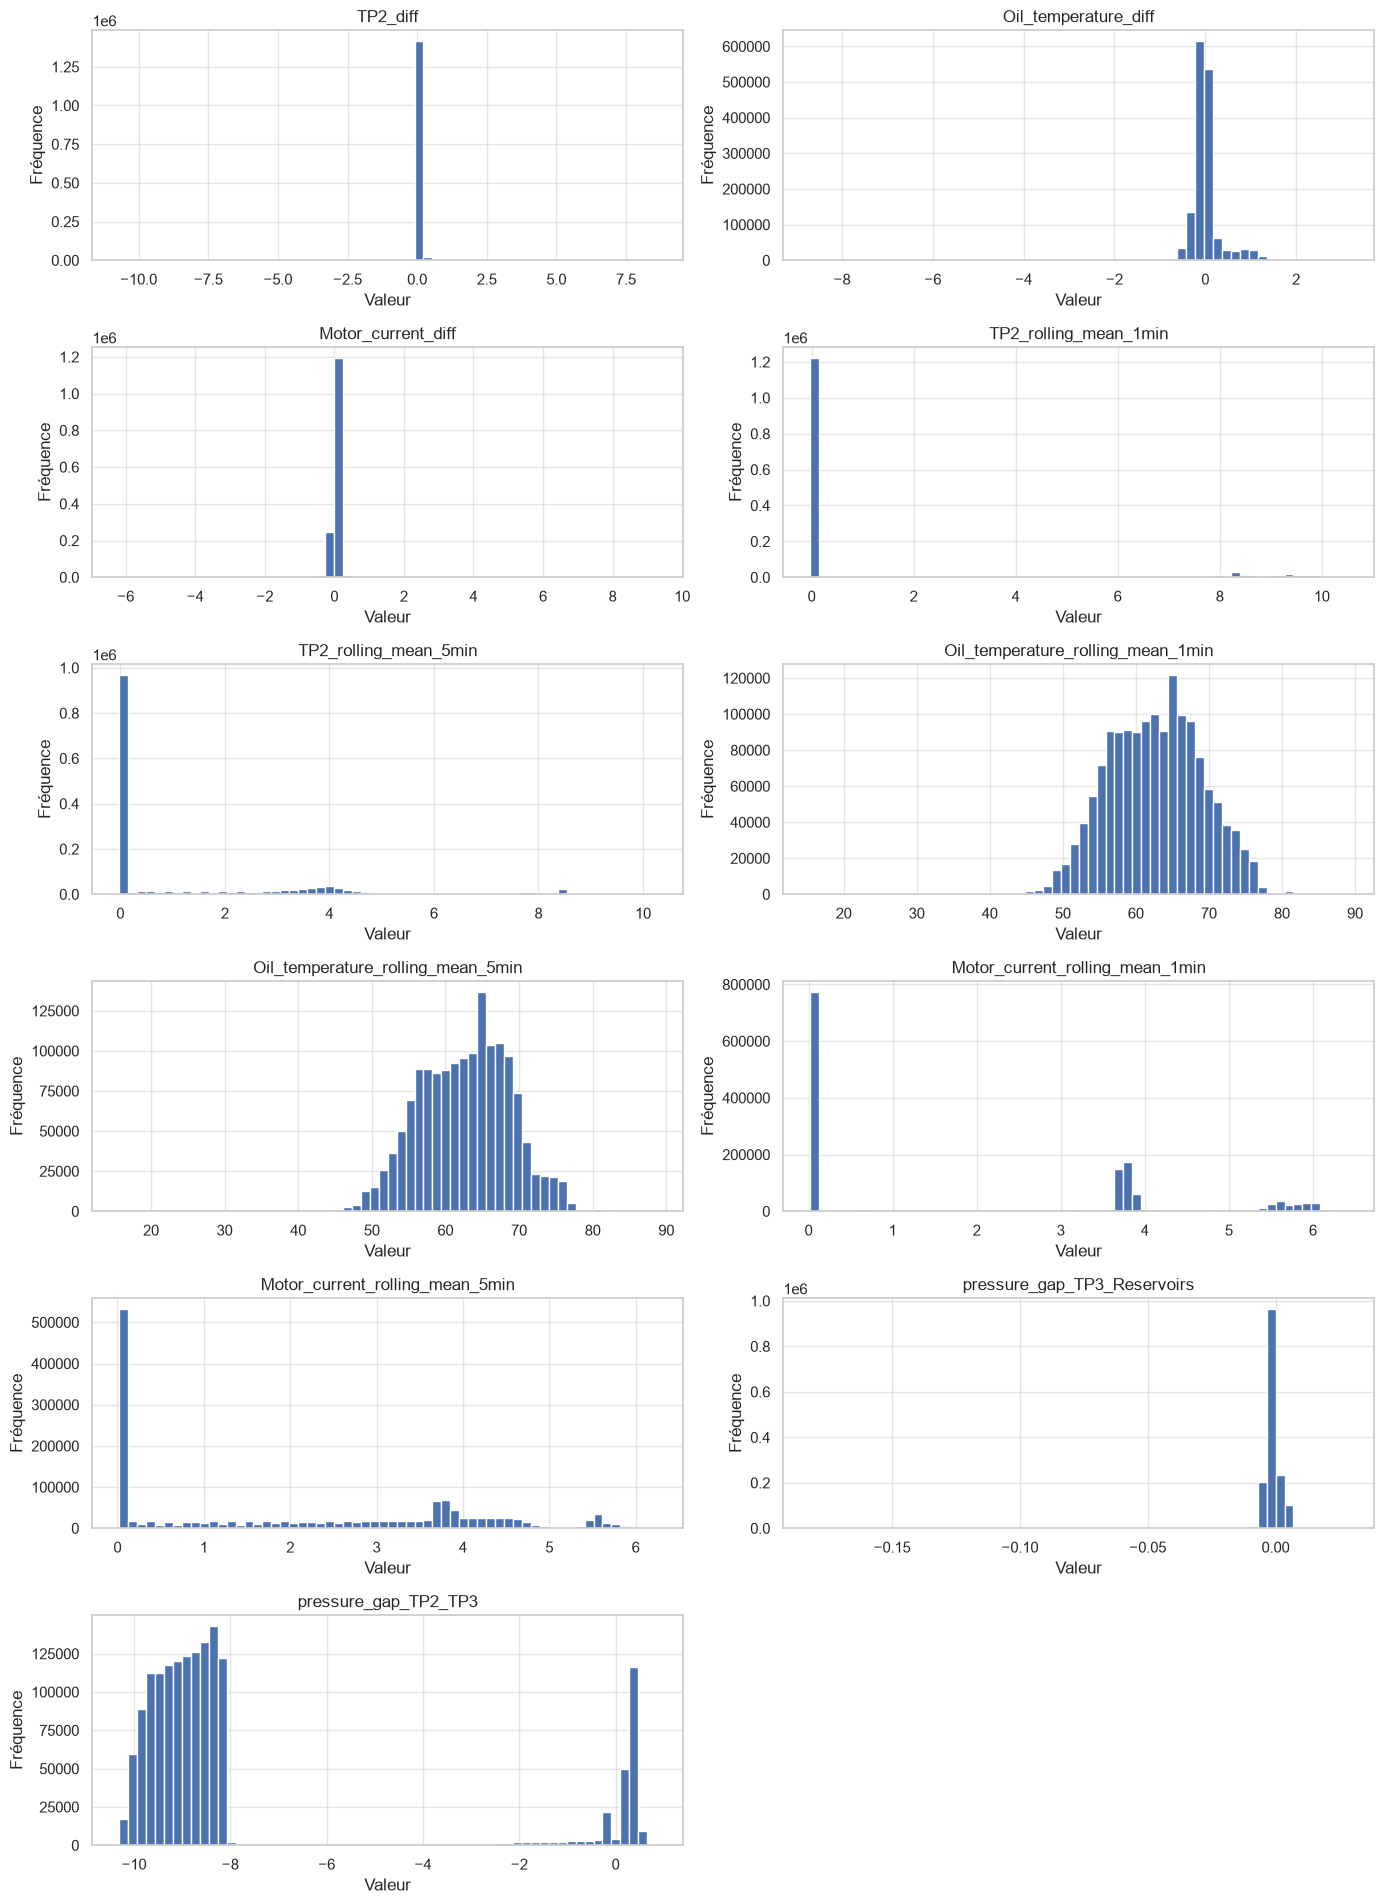

In [11]:
display(df_fe[engineered_features].describe().T)

# Distributions des variables créées.
n_features = len(engineered_features)
ncols = 2
nrows = int(np.ceil(n_features / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, engineered_features):
    values = df_fe[col].dropna()
    ax.hist(values, bins=60)
    ax.set_title(col)
    ax.set_xlabel("Valeur")
    ax.set_ylabel("Fréquence")

for ax in axes[n_features:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


## 10. Corrélations exploratoires entre variables créées et baseline

Cette analyse est descriptive. Une corrélation élevée peut signaler une redondance, mais ne suffit pas à décider de supprimer une variable. La sélection finale sera réalisée dans le cadre d'expériences contrôlées, sans utiliser les données de test pour choisir les variables.

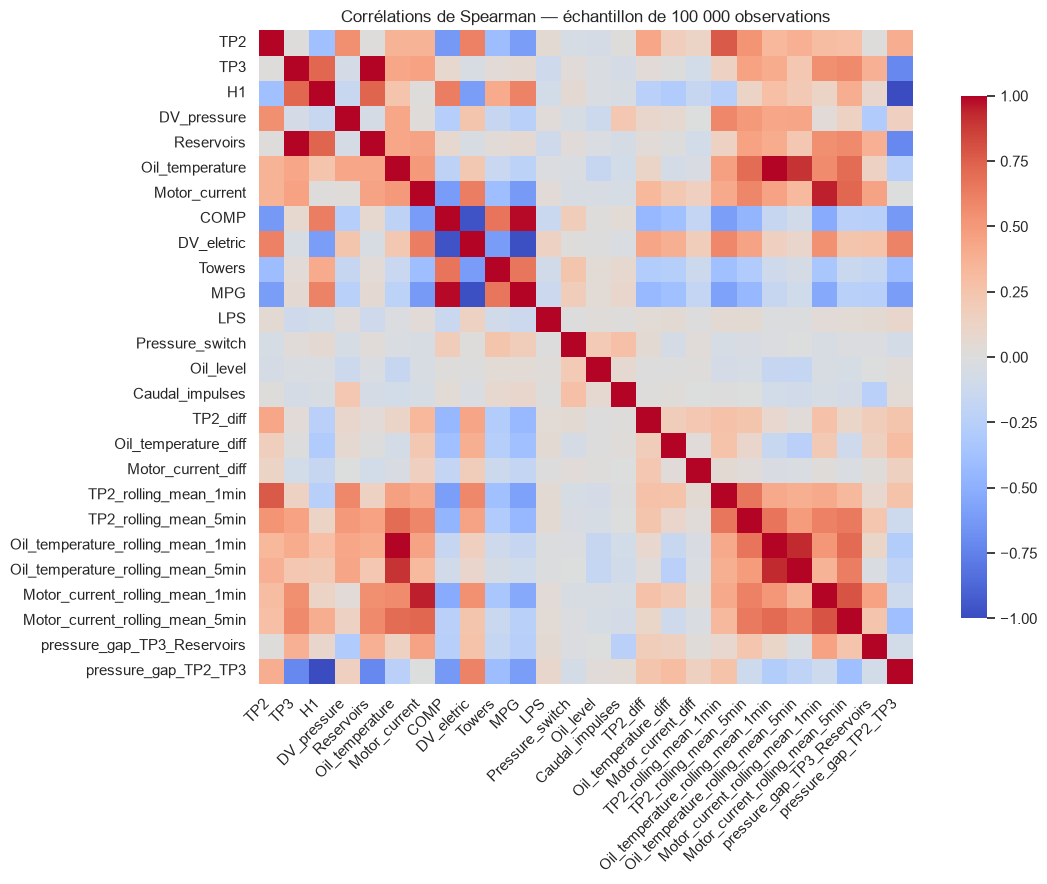

In [15]:
# Échantillonnage pour accélérer le calcul
df_sample = df_fe[correlation_columns].sample(
    n=min(100_000, len(df_fe)),
    random_state=42
)

# Calcul des corrélations
corr = df_sample.corr(method="spearman")

# Affichage simplifié
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0,
    square=True,
    cbar_kws={"shrink": 0.8},
    ax=ax
)

ax.set_title("Corrélations de Spearman — échantillon de 100 000 observations")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

fig.tight_layout()
plt.show()
plt.close(fig)


## 11. Définition des jeux de variables candidats

Nous conservons la liste baseline inchangée. Le jeu enrichi ajoute les variables dérivées. Le notebook de validation/entraînement devra comparer ces deux configurations dans les mêmes folds LOEO.

**Important :** le jeu enrichi est une proposition expérimentale, pas une nouvelle baseline validée.

In [16]:
FEATURE_SET_BASELINE = list(baseline_features)
FEATURE_SET_ENGINEERED = FEATURE_SET_BASELINE + engineered_features

print("Baseline :", len(FEATURE_SET_BASELINE), "variables")
print("Enrichi :", len(FEATURE_SET_ENGINEERED), "variables")

feature_sets = {
    "baseline": FEATURE_SET_BASELINE,
    "baseline_plus_engineering": FEATURE_SET_ENGINEERED,
}


Baseline : 15 variables
Enrichi : 26 variables


## 12. Export du dataset enrichi

L'export est désactivé par défaut pour éviter d'écrire un gros fichier sans validation préalable. Après vérification du notebook, passer `EXPORT_DATASET` à `True`.

Le dataset exporté conserve les colonnes originales, y compris la cible et l'identifiant d'événement pour la traçabilité. Ces colonnes ne doivent jamais être incluses dans `X`.

In [17]:
EXPORT_DATASET = True
OUTPUT_PATH = OUTPUT_DIR / "metropt3_feature_engineered.csv"

if EXPORT_DATASET:
    df_export = df_fe.reset_index()
    df_export.to_csv(OUTPUT_PATH, index=False)
    print("Dataset enrichi exporté :", OUTPUT_PATH)
    print("Dimensions :", df_export.shape)
else:
    print("Export désactivé. Pour exporter après validation : EXPORT_DATASET = True")


Dataset enrichi exporté : C:\Users\ngueb\Desktop\Prédictive_maintenance_MLOPS\data\processed\metropt3_feature_engineered.csv
Dimensions : (1516948, 30)


## Conclusion — Feature Engineering

### Bilan des transformations

Cette étape a permis d'enrichir le dataset MetroPT-3 en construisant 11 nouvelles variables à partir des 15 variables initiales.

Trois familles de variables ont été étudiées :

- **Différences temporelles :** `TP2_diff`, `Oil_temperature_diff` et `Motor_current_diff`, afin de représenter les variations entre observations successives.
- **Moyennes mobiles :** calculées sur des fenêtres temporelles de 1 et 5 minutes pour TP2, Oil_temperature et Motor_current, afin de caractériser les tendances récentes.
- **Interactions physiques :** `pressure_gap_TP3_Reservoirs` et `pressure_gap_TP2_TP3`, afin de représenter les écarts entre certaines mesures de pression.

Le dataset comporte désormais 26 variables candidates : 15 variables initiales et 11 variables dérivées.

###  Contrôle de qualité

Les contrôles réalisés montrent :

- Aucune valeur infinie parmi les nouvelles variables.
- Des taux de valeurs manquantes faibles, compris entre 0 % et 0,0875 %.
- Des valeurs manquantes principalement liées aux différences temporelles et à l'initialisation des fenêtres glissantes.
- Une forte concentration de certaines variables dérivées autour de leurs valeurs habituelles, notamment les différences de pression et de courant.

Les corrélations de Spearman ont été calculées sur un échantillon aléatoire de 100 000 observations. Elles montrent notamment des relations importantes entre les moyennes mobiles et leurs variables d'origine. Ces résultats suggèrent une possible redondance de certaines variables, sans permettre de conclure à leur inutilité.

###  Limites de l'analyse

Les nouvelles variables constituent des candidates à l'amélioration du modèle. Leur utilité prédictive n'a pas encore été démontrée.

Les fenêtres temporelles de 1 et 5 minutes ainsi que le seuil de segmentation de 30 secondes représentent des choix expérimentaux. Ils devront être conservés de manière cohérente dans les futures étapes d'entraînement et d'inférence.

Les transformations devront également être intégrées au futur pipeline de production afin de garantir la reproductibilité des prédictions et l'absence de fuite d'information temporelle.

### Conclusion générale

Le Feature Engineering a permis de construire une première représentation enrichie du comportement du compresseur, en intégrant les variations temporelles, les tendances récentes et certaines relations physiques entre capteurs.

Le dataset enrichi est exporté sous le nom `metropt3_feature_engineered.csv`. Il sera utilisé comme jeu de données expérimental pour les prochaines étapes.

Aucune variable n'est considérée comme définitivement sélectionnée à ce stade.

###  Prochaine étape

Le Notebook 08 sera consacré à la **Feature Selection**. L'objectif sera d'identifier les variables pertinentes, de limiter les redondances et de préparer une comparaison expérimentale entre le modèle de référence et le modèle enrichi, en conservant le même protocole de validation Leave-One-Event-Out (LOEO).